# 1. Median disposable household income by gebied, 2024

In [4]:
import pandas as pd
from IPython.display import display

%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.


In [ ]:
file_path = "Ggwgebieden.xlsx"

df = pd.read_excel(file_path, sheet_name="data")
metadata = pd.read_excel(file_path, sheet_name="metadata")

# Display the first five observations
df.head()

,Year,Geography,Code,Name,Disposable houshold income (median)
0,2011,ggwgebieden,GA01,Centrum-West,25233
1,2012,ggwgebieden,GA01,Centrum-West,25626
2,2013,ggwgebieden,GA01,Centrum-West,25913
3,2014,ggwgebieden,GA01,Centrum-West,26944
4,2015,ggwgebieden,GA01,Centrum-West,27518


In [ ]:
# Select the three variables relevant to the analysis
income_df = df[
    ["Year", "Name", "Disposable houshold income (median)"]
].copy()

# Rename the income column
income_df = income_df.rename(
    columns={
        "Disposable houshold income (median)": 
        "Median disposable household income (€)"
    }
)

income_df.head()

,Year,Name,Median disposable household income (€)
0,2011,Centrum-West,25233
1,2012,Centrum-West,25626
2,2013,Centrum-West,25913
3,2014,Centrum-West,26944
4,2015,Centrum-West,27518


Now we will examine the number of observations, years, and  geographical areas. This confirms whether the dataset corresponds to the expected period of 2011–2024 and contains the 25 GGW areas of Amsterdam. 

In [ ]:
print("Number of observations:", len(income_df))
print("Number of GGW areas:", income_df["Name"].nunique())
print("Number of years:", income_df["Year"].nunique())
print("First year:", income_df["Year"].min())
print("Most recent year:", income_df["Year"].max())

print("\nData types:")
print(income_df.dtypes)

Number of observations: 339
Number of GGW areas: 25
Number of years: 14
First year: 2011
Most recent year: 2024

Data types:
Year                                      int64
Name                                        str
Median disposable household income (€)    int64
dtype: object


"Year" is indeed a numerical and discrete temporal variable, "Name" as categorical/nominal, and income as a numerical variable.

# Data visualization
The following bar chart provides a visualization of the median disposable household income across the 25 neighborhoods in 2024. The areas are ordered from highest to lowest median income to make differences between neighborhoods easier to observe.

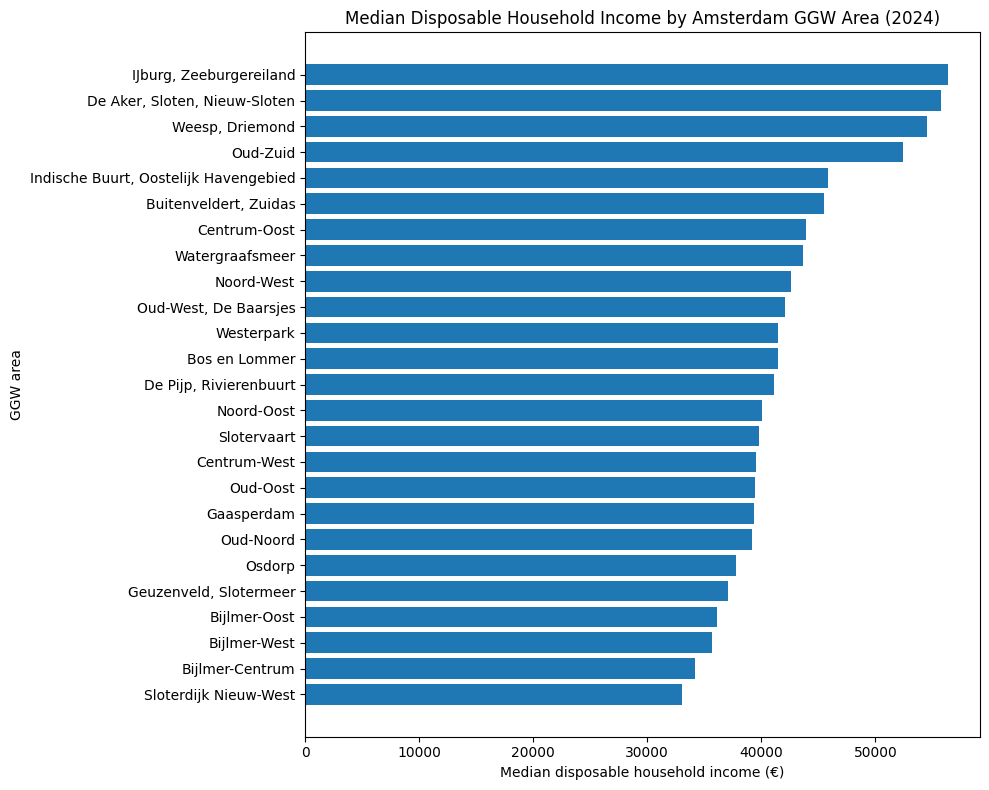

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Select the 2024 observations and sort by income
income_2024 = (
    income_df[income_df["Year"] == 2024]
    .sort_values(
        by="Median disposable household income (€)",
        ascending=True
    )
)

# Create a horizontal bar chart
plt.figure(figsize=(10, 8))

plt.barh(
    income_2024["Name"],
    income_2024["Median disposable household income (€)"]
)

plt.xlabel("Median disposable household income (€)")
plt.ylabel("GGW area")
plt.title("Median Disposable Household Income by Amsterdam GGW Area (2024)")

plt.tight_layout()
plt.show()

# Missing values 

In [ ]:
# Create all possible combinations of years and GGW areas
all_years = range(2011, 2025)
all_areas = income_df["Name"].unique()

complete_index = pd.MultiIndex.from_product(
    [all_years, all_areas],
    names=["Year", "Name"]
)

# Reindex the dataset so that absent year-area combinations appear as NaN
complete_df = (
    income_df
    .set_index(["Year", "Name"])
    .reindex(complete_index)
    .reset_index()
)

# Identify missing observations
missing_data = complete_df[
    complete_df["Median disposable household income (€)"].isna()
]

print("Number of missing year-area observations:", len(missing_data))
print()
print(missing_data[["Year", "Name"]].to_string(index=False))

Number of missing year-area observations: 11

 Year                  Name
 2011 Sloterdijk Nieuw-West
 2011          Bijlmer-West
 2012 Sloterdijk Nieuw-West
 2012          Bijlmer-West
 2013 Sloterdijk Nieuw-West
 2013          Bijlmer-West
 2014 Sloterdijk Nieuw-West
 2014          Bijlmer-West
 2015 Sloterdijk Nieuw-West
 2016 Sloterdijk Nieuw-West
 2017 Sloterdijk Nieuw-West


There are 11 missing year-area observations: Bijlmer-West has no observations between 2011-2014, while Sloterdijk 
Nieuw-West has no observations between 2011-2017.

# 2. Education HBO, WO (%) in Amsterdam 

In [ ]:
import pandas as pd 
import matplotlib.pyplot as plt

In [ ]:
file_path = "Education levels.xlsx"

education = pd.read_excel(
    file_path,
    sheet_name="data",
    engine="openpyxl"
)

metadata = pd.read_excel(
    file_path,
    sheet_name="metadata",
    engine="openpyxl"
)

education.head()

,Year,Geography,Code,Name,"education hbo, wo (%)"
0,2021,ggwgebieden,GA02,Centrum-Oost,62
1,2021,ggwgebieden,GK12,"Buitenveldert, Zuidas",54
2,2021,ggwgebieden,GK11,Oud-Zuid,66
3,2021,ggwgebieden,GF10,Slotervaart,41
4,2021,ggwgebieden,GA01,Centrum-West,62


In [ ]:
education_df = education[
    ["Year", "Name", "education hbo, wo (%)"]]

print("Number of observations:", len(education_df))
print("Number of GGW areas:", education_df["Name"].nunique())
print("Number of years:", education_df["Year"].nunique())
print("First year:", education_df["Year"].min())
print("Most recent year:", education_df["Year"].max())

print("\nData types:")
print(education_df.dtypes)

Number of observations: 356
Number of GGW areas: 25
Number of years: 15
First year: 2010
Most recent year: 2024

Data types:
Year                     int64
Name                       str
education hbo, wo (%)    int64
dtype: object


This verifies and confirms the correct number of areas (25) and the period of the dataset (2010-2024). This also supports the description of the relevant variables: "Year", "Name", and "Education". 

# Missing data
We will investigate all possible combinations of years and areas to identify the missing observations. 

In [ ]:
all_years = range(2010, 2025)
all_areas = education_df["Name"].unique()

complete_index = pd.MultiIndex.from_product(
    [all_years, all_areas],
    names=["Year", "Name"]
)

# Add absent combinations as missing values
complete_df = (
    education_df
    .set_index(["Year", "Name"])
    .reindex(complete_index)
    .reset_index()
)

# Select missing observations
missing_data = complete_df[
    complete_df["education hbo, wo (%)"].isna()
]

print("Number of missing year-area observations:", len(missing_data))
print()

print(
    missing_data
    .groupby("Name")["Year"]
    .apply(list)
)

Number of missing year-area observations: 19

Name
Bijlmer-West                         [2010, 2011, 2012, 2013, 2014]
Sloterdijk Nieuw-West    [2010, 2011, 2012, 2013, 2014, 2015, 2016]
Weesp, Driemond          [2010, 2011, 2012, 2013, 2014, 2015, 2016]
Name: Year, dtype: object


We also want to confirm that all 25 GGW areas contain an education value for 2024 because it is the most recent year available. The following code will check this and for any missing values. 

In [ ]:
education_2024 = education_df[
    education_df["Year"] == 2024
].copy()

print("Number of GGW areas in 2024:", education_2024["Name"].nunique())
print(
    "Missing education values in 2024:",
    education_2024["education hbo, wo (%)"].isna().sum()
)

Number of GGW areas in 2024: 25
Missing education values in 2024: 0


# Checking for any outliers 
Potential outliers are examined using the interquartile range (IQR) method. An observation is considered a potential outlier if it falls below
Q1 - 1.5 × IQR or above Q3 + 1.5 × IQR. 

In [ ]:
Q1 = education_2024["education hbo, wo (%)"].quantile(0.25)
Q3 = education_2024["education hbo, wo (%)"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = education_2024[
    (education_2024["education hbo, wo (%)"] < lower_bound) |
    (education_2024["education hbo, wo (%)"] > upper_bound)
]

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of potential outliers:", len(outliers))

Lower bound: 3.0
Upper bound: 91.0
Number of potential outliers: 0


Therefore, we can confirm that there are no outliers for the 2024 values. 

# Data visualization 
The following graph compares the % of residents aged 15–74 with a completed HBO or WO education across the 25 Amsterdam GGW areas in 2024.

The horiztonal line represents the municipality's reported citywide Amsterdam value of 49%. This makes it possible to compare individual GGW areas with the citywide percentage.

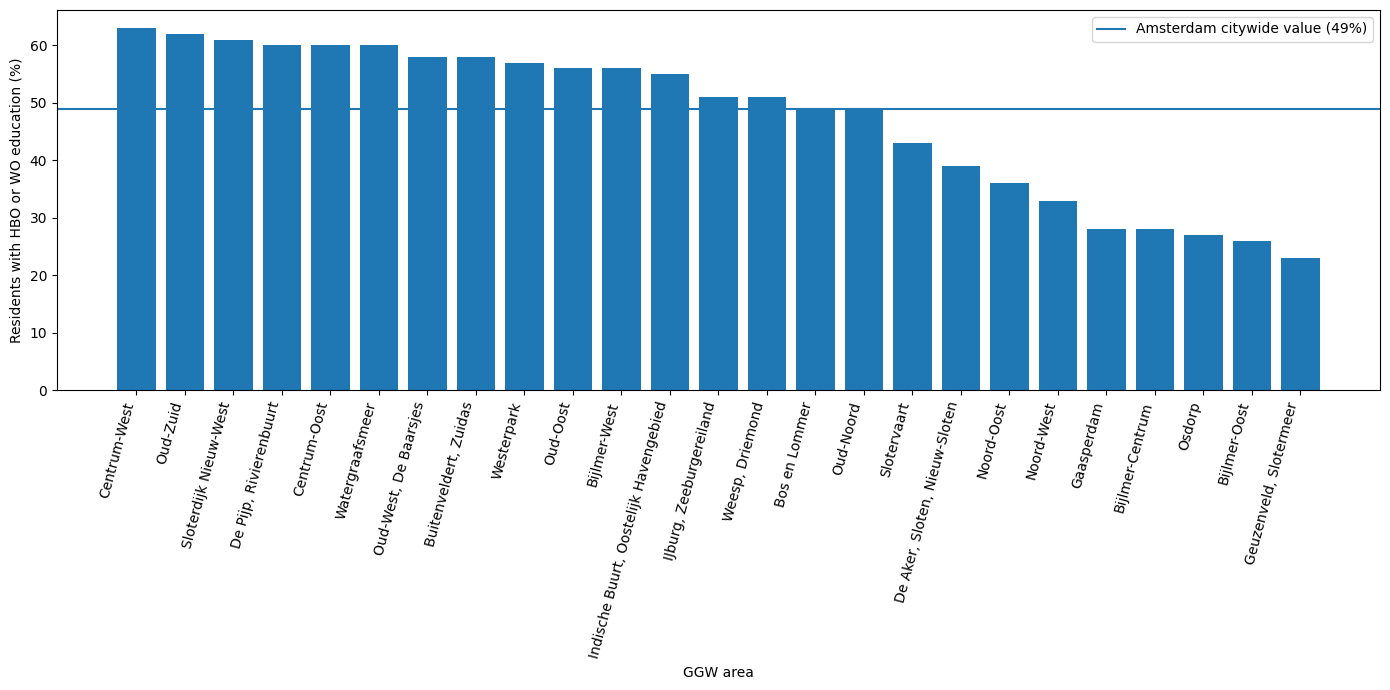

In [ ]:
# Sort areas from lowest to highest education percentage
education_2024_sorted = education_2024.sort_values(
    by="education hbo, wo (%)",
    ascending=False
)

plt.figure(figsize=(14, 7))

plt.bar(
    education_2024_sorted["Name"],
    education_2024_sorted["education hbo, wo (%)"]
)

# Add the Amsterdam citywide percentage
plt.axhline(
    y=49,
    linestyle="-",
    label="Amsterdam citywide value (49%)"
)

plt.xlabel("GGW area")
plt.ylabel("Residents with HBO or WO education (%)")
plt.xticks(rotation=75, ha="right")

plt.legend()
plt.tight_layout()

plt.show()

# 3. Inside Airbnb

In [1]:
import numpy as np
import pandas as pd


In [5]:
data_airbnb = pd.read_csv("listings.csv.gz")

In [7]:
print(data_airbnb.head())

      id                         listing_url       scrape_id last_scraped  \
0  28871  https://www.airbnb.com/rooms/28871  20260615212022   2026-06-16   
1  29051  https://www.airbnb.com/rooms/29051  20260615212022   2026-06-16   
2  44129  https://www.airbnb.com/rooms/44129  20260615212022   2026-06-24   
3  44391  https://www.airbnb.com/rooms/44391  20260615212022   2026-06-24   
4  48373  https://www.airbnb.com/rooms/48373  20260615212022   2026-06-24   

            source                                             name  \
0  previous scrape                          Comfortable double room   
1  previous scrape                 Comfortable single / double room   
2  previous scrape                    Luxury design with canal view   
3  previous scrape  Quiet 2-bedroom Amsterdam city centre apartment   
4  previous scrape              Cozy family home in Amsterdam South   

                                         description  neighborhood_overview  \
0          Basic bedroom in the

In [10]:
df.shape

(10369, 90)

The data set includes 10369 observations each observation represents one listing on airbnb. The data set also includes 90 coloumns each representing a different variable. 

In [11]:
for i, col in enumerate(df.columns, 1):
    print(i, col)

1 id
2 listing_url
3 scrape_id
4 last_scraped
5 source
6 name
7 description
8 neighborhood_overview
9 picture_url
10 host_id
11 host_url
12 host_profile_id
13 host_profile_url
14 host_name
15 host_since
16 hosts_time_as_user_years
17 hosts_time_as_user_months
18 hosts_time_as_host_years
19 hosts_time_as_host_months
20 host_location
21 host_about
22 host_response_time
23 host_response_rate
24 host_acceptance_rate
25 host_is_superhost
26 host_thumbnail_url
27 host_picture_url
28 host_neighbourhood
29 host_listings_count
30 host_total_listings_count
31 host_verifications
32 host_has_profile_pic
33 host_identity_verified
34 neighbourhood
35 neighbourhood_cleansed
36 neighbourhood_group_cleansed
37 latitude
38 longitude
39 property_type
40 room_type
41 accommodates
42 bathrooms
43 bathrooms_text
44 bedrooms
45 beds
46 amenities
47 price
48 price_quote_checkin_date
49 price_quote_checkout_date
50 price_quote_total_price
51 price_quote_price_per_night
52 price_quote_raw
53 minimum_nights
54 m

for the purpose of convenience let's establish these 90 varaibles into distinct categories:
1. listing identification (1-10)
2. host charactarestics (11-33)
3. neighbourhood info (34-38), this catgory is important for our specefied project proposal
4. property charactarestics (39-46), this category also might prove important 
5. price information (47-52), this is the most important group because price is our target variable 
6. booking restrictions and stay charactarestics (53-61)
7. Availability, reviews and estimated activity (62-83)
8. other info (84-90)

In [15]:
data_airbnb.dtypes

id                                                int64
listing_url                                         str
scrape_id                                         int64
last_scraped                                        str
source                                              str
                                                 ...   
calculated_host_listings_count                    int64
calculated_host_listings_count_entire_homes       int64
calculated_host_listings_count_private_rooms      int64
calculated_host_listings_count_shared_rooms       int64
reviews_per_month                               float64
Length: 90, dtype: object

In [14]:
data_airbnb[['price', 'room_type', 'property_type', 'accommodates',
    'bathrooms', 'bedrooms', 'beds', 'minimum_nights',
    'number_of_reviews', 'review_scores_rating']].describe(include='all')

,price,room_type,property_type,accommodates,bathrooms,bedrooms,beds,minimum_nights,number_of_reviews,review_scores_rating
count,6377,10369,10369,10369.000000,5413.000000,9219.000000,5717.000000,10366.000000,10369.000000,9346.000000
unique,2709,4,59,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,$314.00,Entire home/apt,Entire rental unit,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,44,8489,4451,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,2.941364,1.248014,1.634234,1.903096,3.591646,51.703539,4.850425
std,NaN,NaN,NaN,1.278998,0.529313,0.890917,1.533525,14.112109,143.771159,0.243524
min,NaN,NaN,NaN,1.000000,0.500000,0.000000,1.000000,1.000000,0.000000,1.000000
25%,NaN,NaN,NaN,2.000000,1.000000,1.000000,1.000000,1.000000,3.000000,4.800000
50%,NaN,NaN,NaN,2.000000,1.000000,1.000000,1.000000,2.000000,10.000000,4.920000
75%,NaN,NaN,NaN,4.000000,1.500000,2.000000,2.000000,3.000000,32.000000,5.000000


In [ ]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(missing) 

# the above code allows us to ispect which varaibles have non zero missing values ordered from most to least 

host_response_time              10369
neighbourhood                   10369
host_verifications              10369
host_total_listings_count       10369
neighbourhood_group_cleansed    10369
host_neighbourhood              10369
host_thumbnail_url              10369
host_acceptance_rate            10369
host_response_rate              10369
calendar_updated                10369
neighborhood_overview           10369
host_since                      10369
instant_bookable                10369
host_about                       4959
bathrooms                        4956
beds                             4652
price                            3992
price_quote_price_per_night      3992
estimated_revenue_l365d          3992
price_quote_total_price          3992
price_quote_raw                  3861
price_quote_checkin_date         3861
price_quote_checkout_date        3861
host_location                    1372
bedrooms                         1150
review_scores_cleanliness        1024
first_review

Important missing varaibles:

1. bathrooms                        4956
2. beds                             4652
3. price                            3992
4. price_quote_price_per_night      3992
5. estimated_revenue_l365d          3992
6. price_quote_total_price          3992
7. price_quote_raw                  3861
8. bedrooms                         1150



In [34]:
data_airbnb[data_airbnb['price'].isna()][
    ['id','has_availability','availability_365','price','price_quote_price_per_night']
].head(20)


,id,has_availability,availability_365,price,price_quote_price_per_night
1,29051,t,2,NaN,NaN
3,44391,t,0,NaN,NaN
4,48373,t,0,NaN,NaN
8,53921,t,0,NaN,NaN
9,55868,t,0,NaN,NaN
11,80635,t,0,NaN,NaN
15,155548,t,0,NaN,NaN
17,168769,t,0,NaN,NaN
18,171054,t,0,NaN,NaN
22,190943,t,0,NaN,NaN


In [36]:
data_airbnb[data_airbnb['price'].isna()]['availability_365'].mean()

np.float64(6.424599198396794)

<Axes: ylabel='Frequency'>

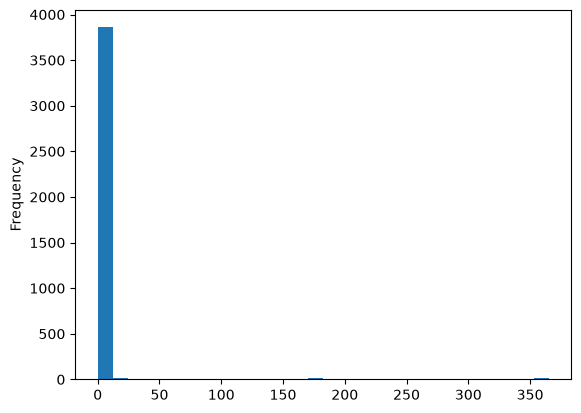

In [42]:
import matplotlib.pyplot as plt

data_airbnb[data_airbnb['price'].isna()]['availability_365'].plot.hist(bins=30)



The graph illustrates that the overwhelming majority of listings with a missing price have an availablity that gravitates around the number 0 which provides insight into the reason why the data is missing in the first place.

In [43]:
df['id'].duplicated().sum()

np.int64(0)

No duplicate IDs which is a good sign 

In [45]:
data_airbnb['minimum_nights'].describe()

count    10366.000000
mean         3.591646
std         14.112109
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
max        800.000000
Name: minimum_nights, dtype: float64

a potential issue we might have to investigate is the max of 800

<Axes: ylabel='Frequency'>

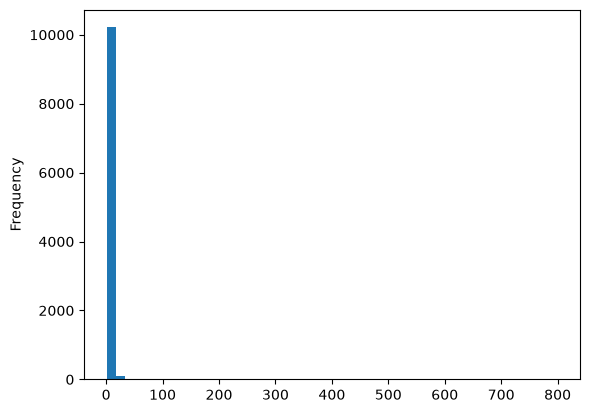

In [48]:
data_airbnb['minimum_nights'].plot.hist(bins=50)

In [49]:
data_airbnb['minimum_nights'].value_counts().sort_index(ascending=False).head(20)

minimum_nights
800.0     1
365.0     3
364.0     2
363.0     2
300.0     1
299.0     1
180.0     1
100.0     1
99.0      1
90.0     23
80.0      1
75.0      1
60.0      1
55.0      1
50.0      1
48.0      1
45.0      2
40.0      1
31.0      3
30.0     30
Name: count, dtype: int64

In [21]:
price_numeric = (
    data_airbnb['price']
    .str.replace('$', '')
    .str.replace(',', '')
    .astype(float)
)
price_numeric.describe()

count     6039.000000
mean       345.064526
std        337.987873
min         29.000000
25%        202.000000
50%        285.250000
75%        407.000000
max      11681.000000
Name: price, dtype: float64

<Axes: ylabel='Frequency'>

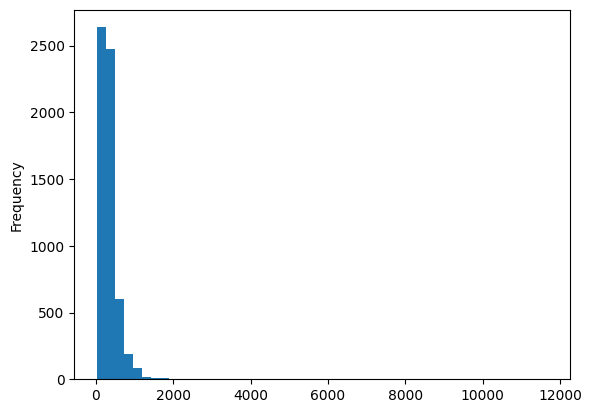

In [22]:
price_numeric.plot.hist(bins=50)

skewed right

In [23]:
price_numeric.sort_values(ascending=False).head(20)

9306    11681.0
245     11581.2
4681     7200.0
4365     7200.0
3402     5706.0
6116     4439.6
1455     3104.0
5754     2678.0
9924     2666.8
1816     2026.0
9483     1983.2
4848     1939.5
4379     1939.0
2448     1938.0
7812     1869.0
2898     1843.0
6153     1832.5
2630     1814.6
8785     1769.0
7755     1754.5
Name: price, dtype: float64

In [25]:
data_airbnb.loc[
    price_numeric.nlargest(20).index,
    [
        "price",
        "host_id",
        "property_type",
        "room_type",
        "accommodates",
        "minimum_nights",
        "bedrooms",
        "bathrooms",
        "beds",
        "neighbourhood_cleansed",
        "listing_url"
    ]
]

,price,host_id,property_type,room_type,accommodates,minimum_nights,bedrooms,bathrooms,beds,neighbourhood_cleansed,listing_url
9306,"$11,681.00",182912442,Entire home,Entire home/apt,4,1.0,2.0,NaN,2.0,De Pijp - Rivierenbuurt,https://www.airbnb.com/rooms/1548025772403046607
245,"$11,581.20",10428722,Entire rental unit,Entire home/apt,2,5.0,1.0,NaN,1.0,Centrum-West,https://www.airbnb.com/rooms/2474754
4365,"$7,200.00",18081564,Boat,Entire home/apt,16,1.0,17.0,NaN,30.0,Oud-Noord,https://www.airbnb.com/rooms/643315499225242586
4681,"$7,200.00",18081564,Boat,Entire home/apt,16,1.0,7.0,NaN,22.0,Oud-Noord,https://www.airbnb.com/rooms/612289973482163299
3402,"$5,706.00",264906709,Entire rental unit,Entire home/apt,2,5.0,1.0,NaN,2.0,Zuid,https://www.airbnb.com/rooms/42910448
6116,"$4,439.60",534378749,Entire home,Entire home/apt,8,5.0,4.0,NaN,4.0,Centrum-West,https://www.airbnb.com/rooms/968203403339639631
1455,"$3,104.00",1791317,Houseboat,Entire home/apt,4,1.0,3.0,NaN,6.0,Centrum-Oost,https://www.airbnb.com/rooms/15304003
5754,"$2,678.00",450136050,Boat,Entire home/apt,8,1.0,3.0,NaN,4.0,IJburg - Zeeburgereiland,https://www.airbnb.com/rooms/925817357449871319
9924,"$2,666.80",17438517,Entire condo,Entire home/apt,6,5.0,3.0,NaN,3.0,Centrum-West,https://www.airbnb.com/rooms/1653697531423374067
1816,"$2,026.00",34339611,Entire home,Entire home/apt,4,1.0,3.0,NaN,4.0,De Pijp - Rivierenbuurt,https://www.airbnb.com/rooms/19885353


This displays the top 20 Airbnb listings with the highest numeric prices together with the other selected listing characteristics, such as the property type, host ID number, etc. 

# 4. Merging the datasets
Firstly, the 3 datasets have different units of observation. The Inside Airbnb dataset contains one observation per Airbnb listing, while the income and education datasets contain one observation per GGW area and year. 

To combine the datasets without accidentally duplicating the Airbnb listings across multiple years, we will use the 2024 observations from the income and education datasets, because it is most recent year. 

The 2024 income and education values will first be combined at the GGW area level. These neighborhood-level characteristics will then be added to each Airbnb listing, based on the listing's 'neighbourhood_cleansed' variable. 

The income and education variables should be interpreted as the most recently available neighborhood characteristics, instead of measurements from the same year as the Airbnb data (2026). 

In [ ]:
# Preparing the income dataset for merging
import pandas as pd 

if "income_df" not in globals():
    file_path = "Ggwgebieden.xlsx"
    df = pd.read_excel(file_path, sheet_name="data")
    income_df = df[
        ["Year", "Name", "Disposable houshold income (median)"]
    ].copy()
    income_df = income_df.rename(
        columns={
            "Disposable houshold income (median)": "Median disposable household income (€)"
        }
    )

income_2024 = income_df[income_df["Year"] == 2024].copy()
income_merge = (
    income_df.loc[
        income_df["Year"] == 2024,
        ["Name", "Median disposable household income (€)"]
    ]
    .rename(columns={"Name": "GGW_area_income"})
    .copy()
)

# Preparing the education dataset 
if "education_df" not in globals():
    education = pd.read_excel(
        "Education levels.xlsx",
        sheet_name="data",
        engine="openpyxl"
    )
    education_df = education[["Year", "Name", "education hbo, wo (%)"]].copy()

education_merge = (
    education_df.loc[
        education_df["Year"] == 2024,
        ["Name", "education hbo, wo (%)"]
    ]
    .rename(
        columns={
            "Name": "GGW_area_education",
            "education hbo, wo (%)": "Higher education (HBO/WO) (%)"
        }
    )
    .copy()
)

print("Income areas in 2024:", len(income_merge))
print("Education areas in 2024:", len(education_merge))

Income areas in 2024: 25
Education areas in 2024: 25


Both datasets contain 25 GGW areas, so this confirms that all expected Amsterdam GGW areas are represented in the datasets before standardizing the neighborhood names and merging the data.

# Comparing geographic areas across the datasets
Before merging the datasets, the geographic area names must be compared. The municipality datasets use GGW areas, while the Airbnb dataset uses the variable 'neighbourhood_cleansed'.

Although some area names may be identical across the datasets, others may differ because the datasets use different geographic classifications. Therefore, we first identify which Airbnb neighborhood names directly correspond to the GGW areas and which remain unmatched.

In [ ]:
# Display the area names

print("Income GGW areas:")
print(sorted(income_merge["GGW_area_income"].unique()))

print("\nEducation GGW areas:")
print(sorted(education_merge["GGW_area_education"].unique()))


data_airbnb = pd.read_csv("listings.csv")
print("\nAirbnb neighborhoods:")
print(sorted(data_airbnb["neighbourhood_cleansed"].dropna().unique()))

Income GGW areas:
['Bijlmer-Centrum', 'Bijlmer-Oost', 'Bijlmer-West', 'Bos en Lommer', 'Buitenveldert, Zuidas', 'Centrum-Oost', 'Centrum-West', 'De Aker, Sloten, Nieuw-Sloten', 'De Pijp, Rivierenbuurt', 'Gaasperdam', 'Geuzenveld, Slotermeer', 'IJburg, Zeeburgereiland', 'Indische Buurt, Oostelijk Havengebied', 'Noord-Oost', 'Noord-West', 'Osdorp', 'Oud-Noord', 'Oud-Oost', 'Oud-West, De Baarsjes', 'Oud-Zuid', 'Sloterdijk Nieuw-West', 'Slotervaart', 'Watergraafsmeer', 'Weesp, Driemond', 'Westerpark']

Education GGW areas:
['Bijlmer-Centrum', 'Bijlmer-Oost', 'Bijlmer-West', 'Bos en Lommer', 'Buitenveldert, Zuidas', 'Centrum-Oost', 'Centrum-West', 'De Aker, Sloten, Nieuw-Sloten', 'De Pijp, Rivierenbuurt', 'Gaasperdam', 'Geuzenveld, Slotermeer', 'IJburg, Zeeburgereiland', 'Indische Buurt, Oostelijk Havengebied', 'Noord-Oost', 'Noord-West', 'Osdorp', 'Oud-Noord', 'Oud-Oost', 'Oud-West, De Baarsjes', 'Oud-Zuid', 'Sloterdijk Nieuw-West', 'Slotervaart', 'Watergraafsmeer', 'Weesp, Driemond', 'Wes

In [10]:
# Compare Airbnb neighborhood names with the GGW area names

ggw_areas = set(income_merge["GGW_area_income"])

airbnb_areas = set(
    data_airbnb["neighbourhood_cleansed"].dropna()
)

matching_areas = sorted(airbnb_areas & ggw_areas)
unmatched_areas = sorted(airbnb_areas - ggw_areas)

print("Matching neighborhood names:")
print(matching_areas)

print("\nAirbnb neighborhoods without an exact GGW match:")
print(unmatched_areas)

Matching neighborhood names:
['Bijlmer-Centrum', 'Bijlmer-Oost', 'Bos en Lommer', 'Centrum-Oost', 'Centrum-West', 'Noord-Oost', 'Noord-West', 'Osdorp', 'Oud-Noord', 'Oud-Oost', 'Slotervaart', 'Watergraafsmeer', 'Westerpark']

Airbnb neighborhoods without an exact GGW match:
['Buitenveldert - Zuidas', 'De Aker - Nieuw Sloten', 'De Baarsjes - Oud-West', 'De Pijp - Rivierenbuurt', 'Gaasperdam - Driemond', 'Geuzenveld - Slotermeer', 'IJburg - Zeeburgereiland', 'Oostelijk Havengebied - Indische Buurt', 'Zuid']


This comparison shows that 13 Airbnb neighborhood names exactly match GGW area names and 9 do not. 

However, some differences may only result from inconsistent punctuation or formatting between the datasets. For example, the education and income datasets use 'Buitenveldert, Zuidas' while the Airbnb dataset uses 'Buitenveldert - Zuidas'. 

Therefore, we will convert the area names to lowercase and use similar separators (commas, slashes) consistently. For example, 'Buitenveldert, Zuidas' will beomce 'buitenveldert zuidas'. 

In [11]:
def standardize_area_name(series):
    return (
        series.astype("string")
        .str.strip()
        .str.lower()
        # Treat different separators in the same way
        .str.replace(r"\s*[-–—,/]\s*", " ", regex=True)
        # Remove repeated spaces
        .str.replace(r"\s+", " ", regex=True)
    )


income_merge["area_key"] = standardize_area_name(
    income_merge["GGW_area_income"]
)

# Create standardized names in the education dataset
education_merge["area_key"] = standardize_area_name(
    education_merge["GGW_area_education"]
)

# Create standardized names in the Airbnb dataset
data_airbnb["area_key"] = standardize_area_name(
    data_airbnb["neighbourhood_cleansed"]
)

In [ ]:
# Verifying the standardization
print("Municipality example:")
print(
    income_merge.loc[
        income_merge["GGW_area_income"] == "Buitenveldert, Zuidas",
        ["GGW_area_income", "area_key"]
    ]
)

print("\nAirbnb example:")
print(
    data_airbnb.loc[
        data_airbnb["neighbourhood_cleansed"] == "Buitenveldert - Zuidas",
        ["neighbourhood_cleansed", "area_key"]
    ].head(1)
)

Municipality example:
           GGW_area_income              area_key
160  Buitenveldert, Zuidas  buitenveldert zuidas

Airbnb example:
   neighbourhood_cleansed              area_key
3  Buitenveldert - Zuidas  buitenveldert zuidas


In [13]:
# Create sets of standardized GGW and Airbnb area names
ggw_areas = set(income_merge["area_key"].dropna())

airbnb_areas = set(data_airbnb["area_key"].dropna())

# Identify matching and unmatched standardized area names
matching_areas = sorted(airbnb_areas & ggw_areas)
unmatched_areas = sorted(airbnb_areas - ggw_areas)

print("Number of matching Airbnb neighborhoods:", len(matching_areas))

print("\nMatching standardized neighborhood names:")
print(matching_areas)

print("\nAirbnb neighborhoods still without a GGW match:")
print(unmatched_areas)

Number of matching Airbnb neighborhoods: 17

Matching standardized neighborhood names:
['bijlmer centrum', 'bijlmer oost', 'bos en lommer', 'buitenveldert zuidas', 'centrum oost', 'centrum west', 'de pijp rivierenbuurt', 'geuzenveld slotermeer', 'ijburg zeeburgereiland', 'noord oost', 'noord west', 'osdorp', 'oud noord', 'oud oost', 'slotervaart', 'watergraafsmeer', 'westerpark']

Airbnb neighborhoods still without a GGW match:
['de aker nieuw sloten', 'de baarsjes oud west', 'gaasperdam driemond', 'oostelijk havengebied indische buurt', 'zuid']


After standardizing the geographic area names, the number of matching neighborhoods between the Airbnb dataset and the GGW datasets increased from 13 to 17. This indicates that 4 of the previously unmatched neighborhoods differed only because of formatting or punctuation: 'buitenveldert zuidas', 'de pijp rivierenbuurt', 'geuzenveld slotermeer', and 'ijburg zeeburgereiland'. 

There are now 5 Airbnb neighborhoods that still do not have a direct match with the GGW area names. These remaining cases should remain as they are rather than being assigned potentially incorrect socioeconomic values and influencing the findings of the project.

### Next steps: 
1. The income and education datasets will first be merged using the standardized area_key, creating one socioeconomic dataset with one row per GGW area.
2. This socioeconomic dataset will then be merged with the Airbnb dataset using the same area_key. A many-to-one merge will be used because multiple Airbnb listings can belong to the same GGW area, while each GGW area has only one set of income and education values. 
3. The number of rows will be checked to ensure that Airbnb listings have not been duplicated, and missing socioeconomic values will be examined to identify any listings that could not be matched. 

In [ ]:
socio_2024 = income_merge.merge(
    education_merge,
    on="area_key",
    how="outer",
    validate="one_to_one",
    indicator=True
)

# Check if each area is present in both datasets
print("Merge result:")
print(socio_2024["_merge"].value_counts())

# Create a GGW-area column
socio_2024["GGW_area"] = (
    socio_2024["GGW_area_income"]
    .combine_first(socio_2024["GGW_area_education"])
)

# Keep only the variables needed for the Airbnb merge
socio_2024 = socio_2024[
    [
        "area_key",
        "GGW_area",
        "Median disposable household income (€)",
        "Higher education (HBO/WO) (%)"
    ]
].copy()


matching_neighborhoods = (
    data_airbnb[
        data_airbnb["area_key"].isin(socio_2024["area_key"])
    ][["neighbourhood_cleansed", "area_key"]]
    .drop_duplicates()
    .merge(
        socio_2024,
        on="area_key",
        how="inner"
    )
    .sort_values("neighbourhood_cleansed")
    .reset_index(drop=True)
)


display(
    matching_neighborhoods[
        [
            "neighbourhood_cleansed",
            "GGW_area",
            "Median disposable household income (€)",
            "Higher education (HBO/WO) (%)"
        ]
    ]
)

print(
    "Number of matching Airbnb neighborhoods:",
    matching_neighborhoods["area_key"].nunique()
)

Merge result:
_merge
both          25
left_only      0
right_only     0
Name: count, dtype: int64


,neighbourhood_cleansed,GGW_area,Median disposable household income (€),Higher education (HBO/WO) (%)
0,Bijlmer-Centrum,Bijlmer-Centrum,34190,28
1,Bijlmer-Oost,Bijlmer-Oost,36108,26
2,Bos en Lommer,Bos en Lommer,41424,49
3,Buitenveldert - Zuidas,"Buitenveldert, Zuidas",45456,58
4,Centrum-Oost,Centrum-Oost,43924,60
5,Centrum-West,Centrum-West,39545,63
6,De Pijp - Rivierenbuurt,"De Pijp, Rivierenbuurt",41125,60
7,Geuzenveld - Slotermeer,"Geuzenveld, Slotermeer",37120,23
8,IJburg - Zeeburgereiland,"IJburg, Zeeburgereiland",56355,51
9,Noord-Oost,Noord-Oost,40104,36


Number of matching Airbnb neighborhoods: 17


The table above shows all 17 Airbnb neighborhood categories that were matched to a GGW area after standardizing the geographic area names. Both the original Airbnb neighborhood name and the corresponding GGW area name verify that the geographic matching was performed correctly. The associated income and education values are also included.

In [17]:
# Merge the Airbnb listings with the socioeconomic dataset
merged_df = data_airbnb.merge(
    socio_2024,
    on="area_key",
    how="left",
    validate="many_to_one",
    indicator="_socio_merge"
)

print("Number of Airbnb listings before merge:", len(data_airbnb))
print("Number of rows after merge:", len(merged_df))

print("\nMerge result:")
print(merged_df["_socio_merge"].value_counts())

Number of Airbnb listings before merge: 10612
Number of rows after merge: 10612

Merge result:
_socio_merge
both          7498
left_only     3114
right_only       0
Name: count, dtype: int64


In [18]:
len(data_airbnb) == len(merged_df)

True

This compares the number of rows in the original Airbnb dataset with the number of rows in the merged dataset. The result is True, which means that the merge preserved the same number of Airbnb listings: 10,612 listings. Thus, no listings were accidentally removed or duplicated during the merging process. 

### Analysis: 
-   7,498 listings were matched to a GGW area in Amsterdam 
-   3,114 listings were not matched because their Airbnb neighborhood that do not have a direct match with the GGW area names
-   7,489/10,612 x 100 = 70.7, so approximately 70.7% of the Airbnb listings can be predicted using the socioeconomic data from the income and education datasets
-   3,114/10,612 x 100 = 29.3, so approximately 29.3% of the Airbnb listings do not have income and education values after the merge 

# Converting Airbnb prices to numerical values 
The Airbnb 'price' variable contains currency symbols and commas and is therefore stored as a text variable. Earlier in the analysis, these characters were removed to convert the listing prices into numerical values.

Since all of the datasets have now been merged, the same conversion is applied directly to the 'price' column in 'merged_df'. A new variable, 'price_numeric', is created so that Airbnb prices can be used in subsequent statistical analyses and predictive models while the original 'price' variable is retained.

In [19]:

merged_df["price_numeric"] = (
    merged_df["price"]
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .astype(float)
)

# Check the numerical price variable
merged_df["price_numeric"].describe()

count     6039.000000
mean       345.064526
std        337.987873
min         29.000000
25%        202.000000
50%        285.250000
75%        407.000000
max      11681.000000
Name: price_numeric, dtype: float64

'describe()' automatically excludes missing values, so a count of 6,039 means that there are 6,039 listings with an available numerical price. 

In [26]:
print("Total Airbnb listings:", len(merged_df))
print("Listings with a price:", merged_df["price_numeric"].notna().sum())
print("Listings without a price:", merged_df["price_numeric"].isna().sum())

Total Airbnb listings: 10612
Listings with a price: 6039
Listings without a price: 4573
